# Import Statements

In [8]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import FortranFile
import smplotlib
from hmf import MassFunction
from astropy.cosmology import FlatLambdaCDM, Planck18
import pandas as pd


# Path

In [9]:
root = Path("../").resolve()
tree_dir = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/binary_tree_n_progenitors_mh8to14_2_not_mine")
results = root / "Results_600"
zgrid = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/redshift_grid_mh8to14.bin")
models = {"fiducial", "eSFE", "eIMF"}
for model in models:
    print(model, sorted(p.name for p in results.glob(f"{model}_seed*")))


fiducial ['fiducial_seed12345', 'fiducial_seed13579', 'fiducial_seed24680', 'fiducial_seed32889', 'fiducial_seed98765']
eSFE ['eSFE_seed12345', 'eSFE_seed13579', 'eSFE_seed24680', 'eSFE_seed32889', 'eSFE_seed98765']
eIMF ['eIMF_seed12345', 'eIMF_seed13579', 'eIMF_seed24680', 'eIMF_seed32889', 'eIMF_seed98765']


# Mass Function Definitions

In [10]:
Om, Ob, h = 0.30966, 0.04897, 0.6766   # same cosmology as module_constants.f90 and figure7.ipynb
cosmo = FlatLambdaCDM(H0=100*h, Om0=Om, Ob0=Ob, Tcmb0=2.7255)

mass_function = MassFunction(z=4.5, cosmo_model=cosmo,
                            sigma_8=0.811, n=0.965,
                            hmf_model="ST", transfer_model="EH",
                            Mmin=7.5, Mmax=14.5, dlog10m=0.01,
                            )

logM_st = np.log10(mass_function.m / h)
# dn/dlnM (not dn/dlog10M) is the normalisation behind the paper's figures, as in figure7.ipynb and stellar_mass_function.ipynb
phi_st = mass_function.dndlnm * h**3
dlogM_tree = 0.01          # the 600 trees are spaced by 0.01 dex, from 10^8.00 to 10^13.99 Msun
logM = []
weight = []

In [11]:
with FortranFile(zgrid, "r") as f:
    _ = f.read_ints(np.int32)
    redshifts = f.read_reals(np.float64)

z_targets = [5, 7, 8, 9, 10, 11, 12, 14]
z_use = [int(np.argmin(np.abs(redshifts - zt)) + 1) for zt in z_targets]

logM = {z_i: [] for z_i in z_use}
weight = {z_i: [] for z_i in z_use}

for p in sorted(tree_dir.glob("merger_tree_*")):
    with FortranFile(p, "r") as f:
        _n = int(f.read_ints(np.int32)[0])
        redshift_index_of_halos = f.read_ints(np.int32)
        mass_halos = f.read_reals(np.float64)
    mass_of_descendants = mass_halos[redshift_index_of_halos == 1]
    logM_descendant = np.log10(mass_of_descendants)
    weight_i = np.interp(logM_descendant, logM_st, phi_st) * dlogM_tree
    for z_i in z_use:
        sel = redshift_index_of_halos == z_i
        mass_at_z = mass_halos[sel]
        if mass_at_z.size == 0:
            continue
        #array that is the same length as the halos selected, with every entry equal to this tree’s weight_i
        logM[z_i].append(np.log10(mass_at_z))
        weight[z_i].append(np.full(mass_at_z.size, weight_i))

for z_i in z_use:
    logM[z_i] = np.concatenate(logM[z_i])
    weight[z_i] = np.concatenate(weight[z_i])

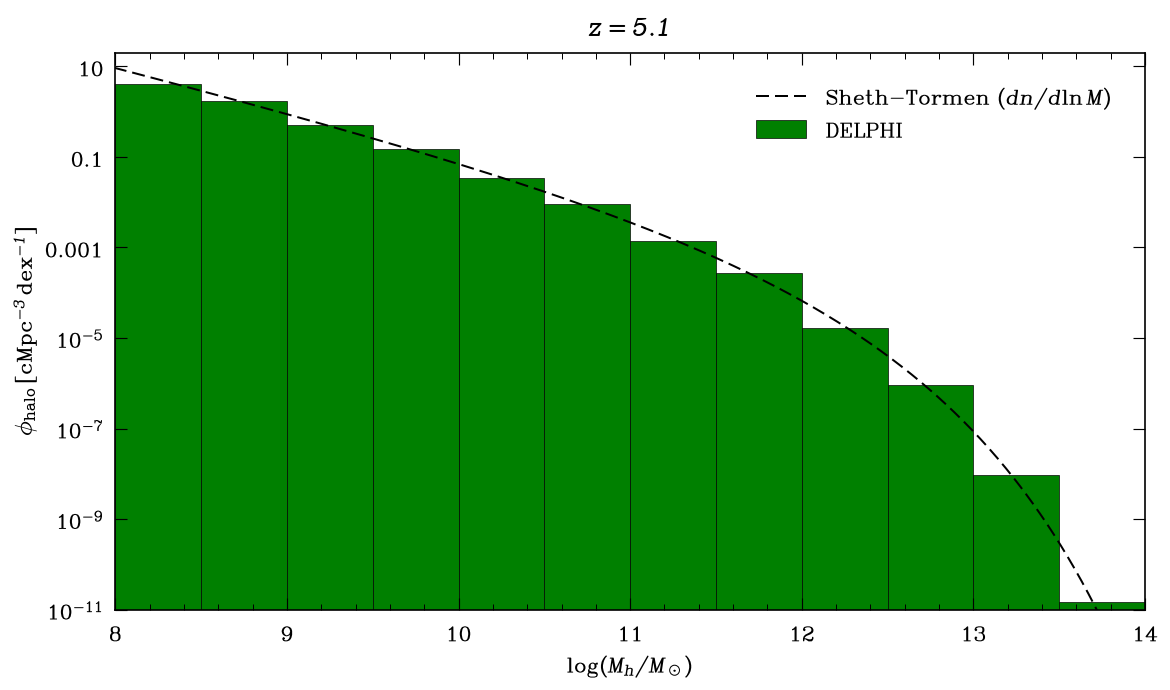

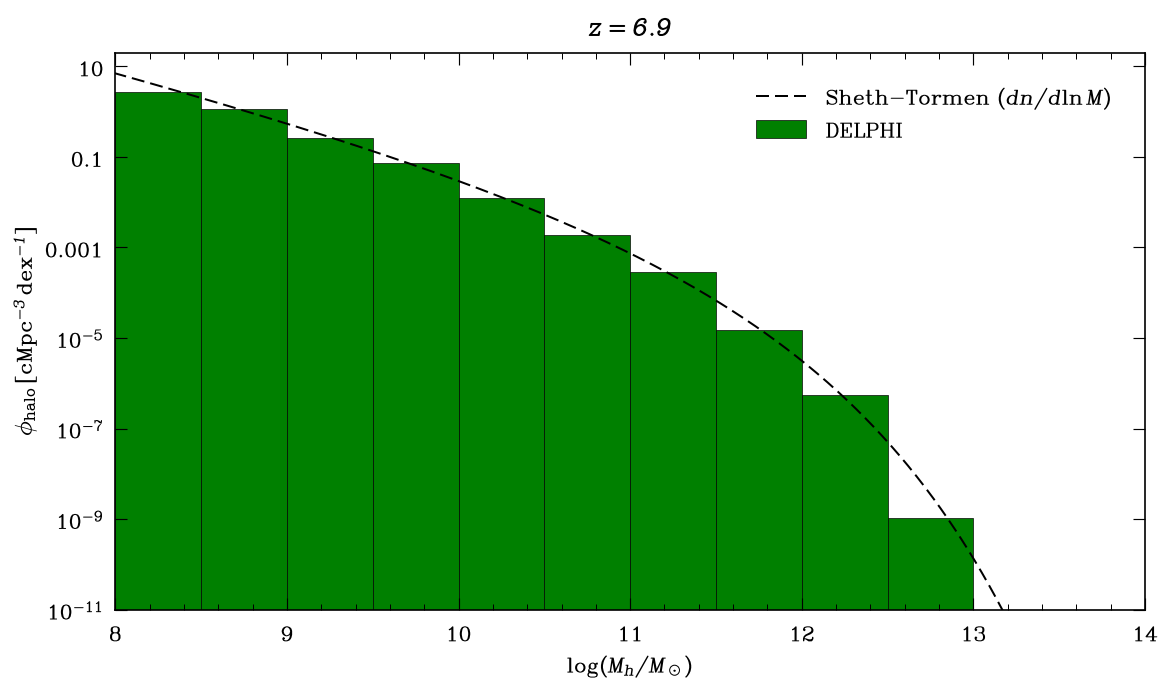

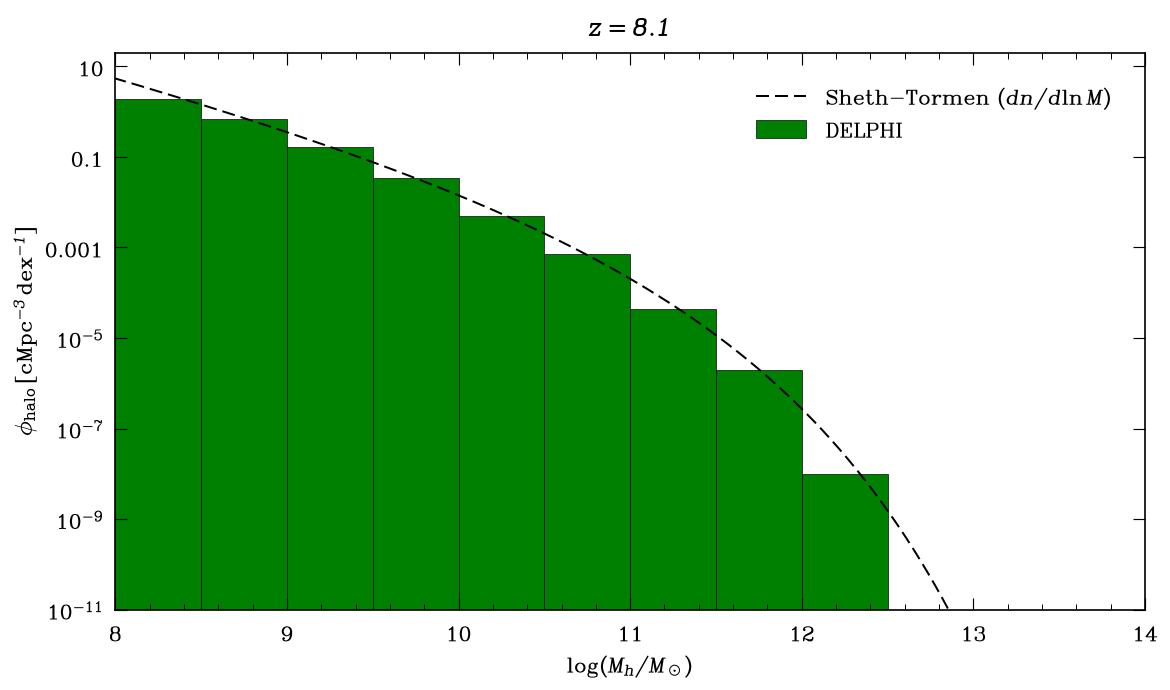

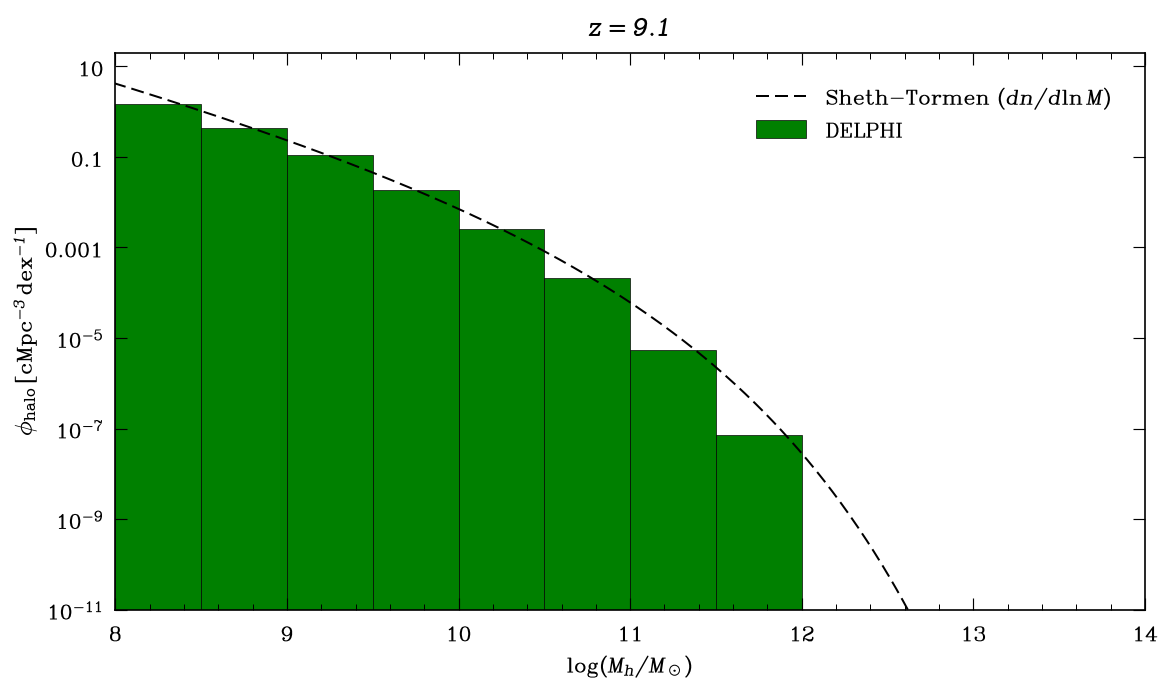

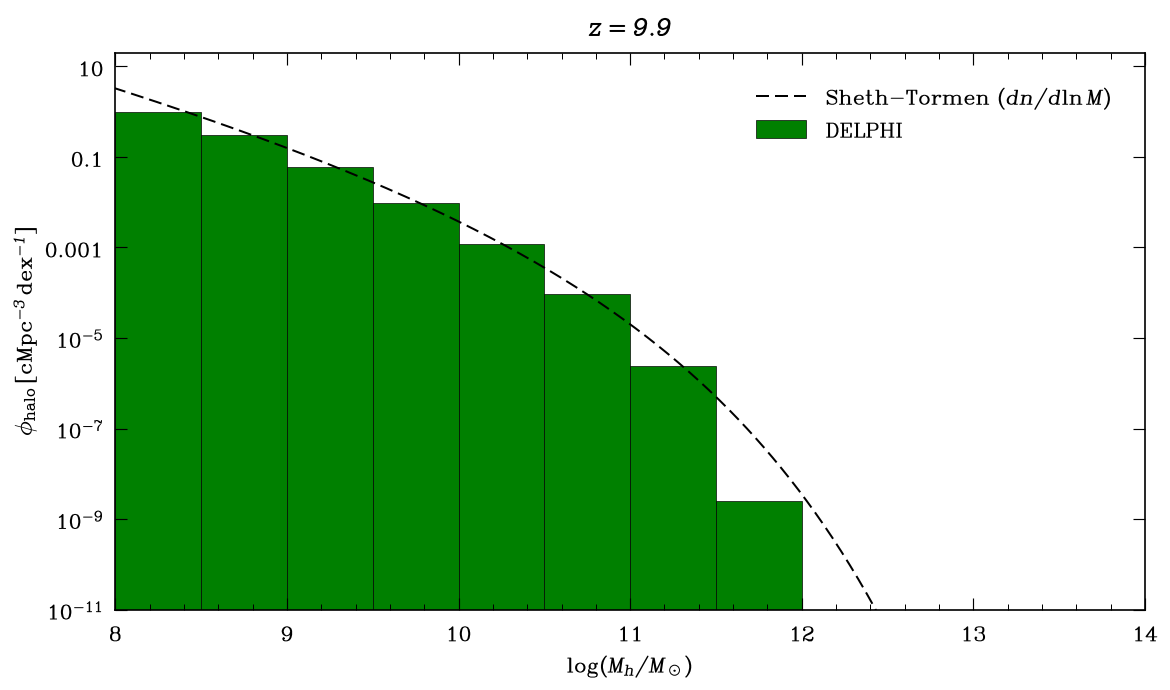

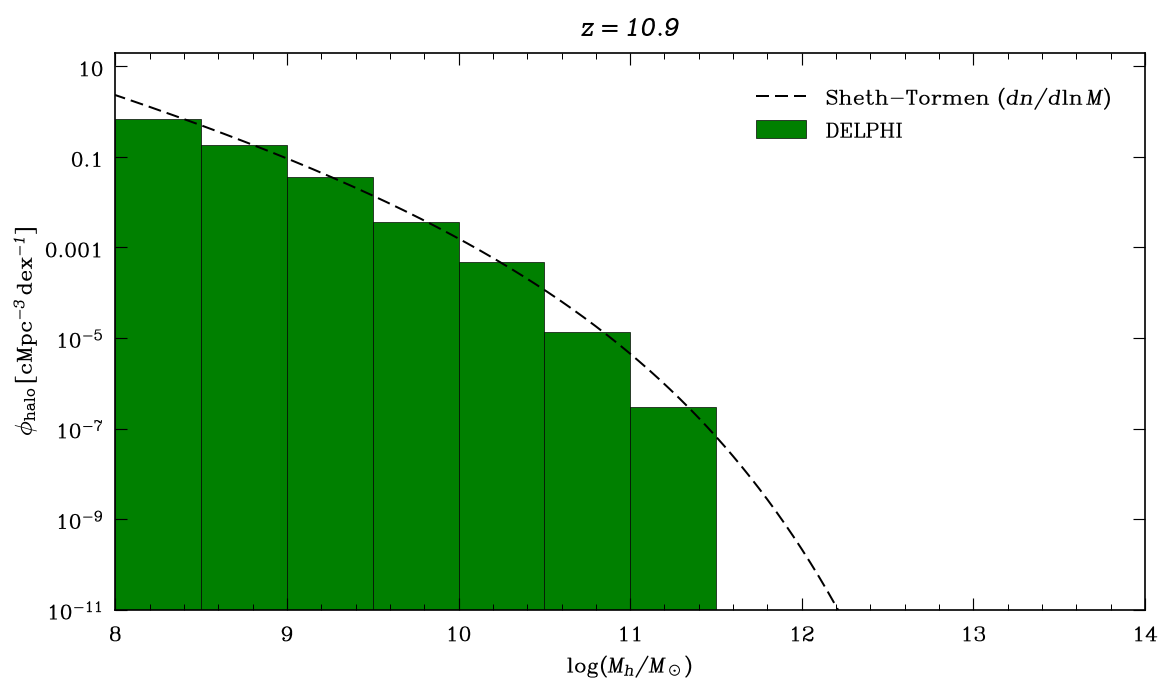

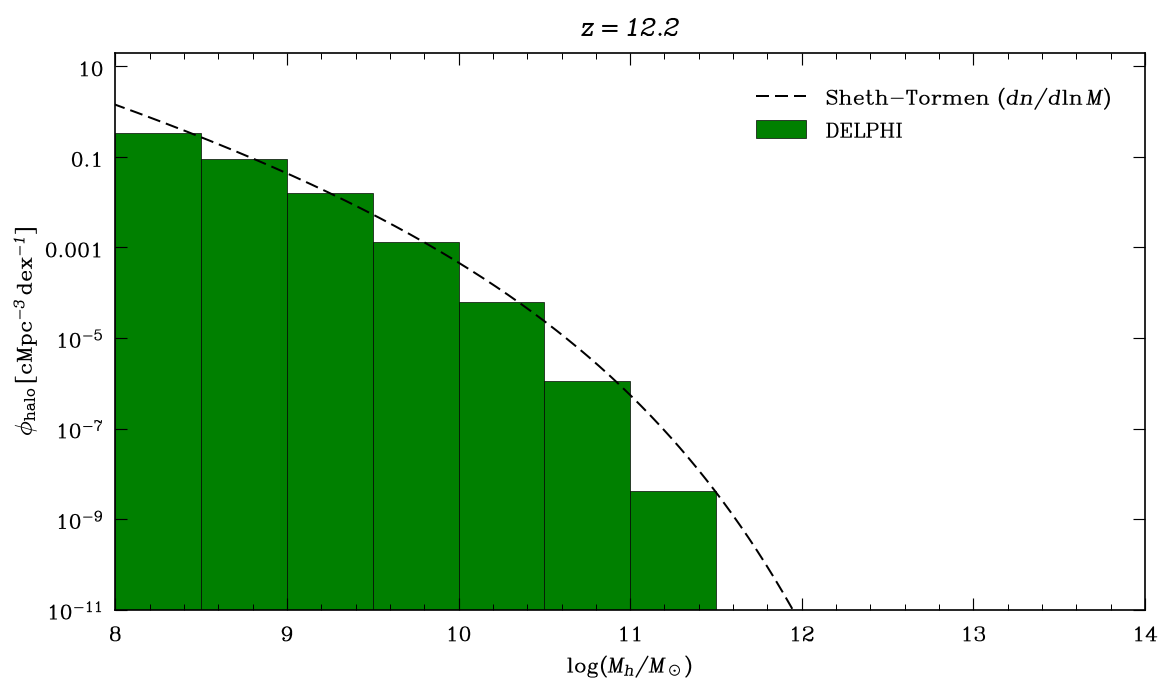

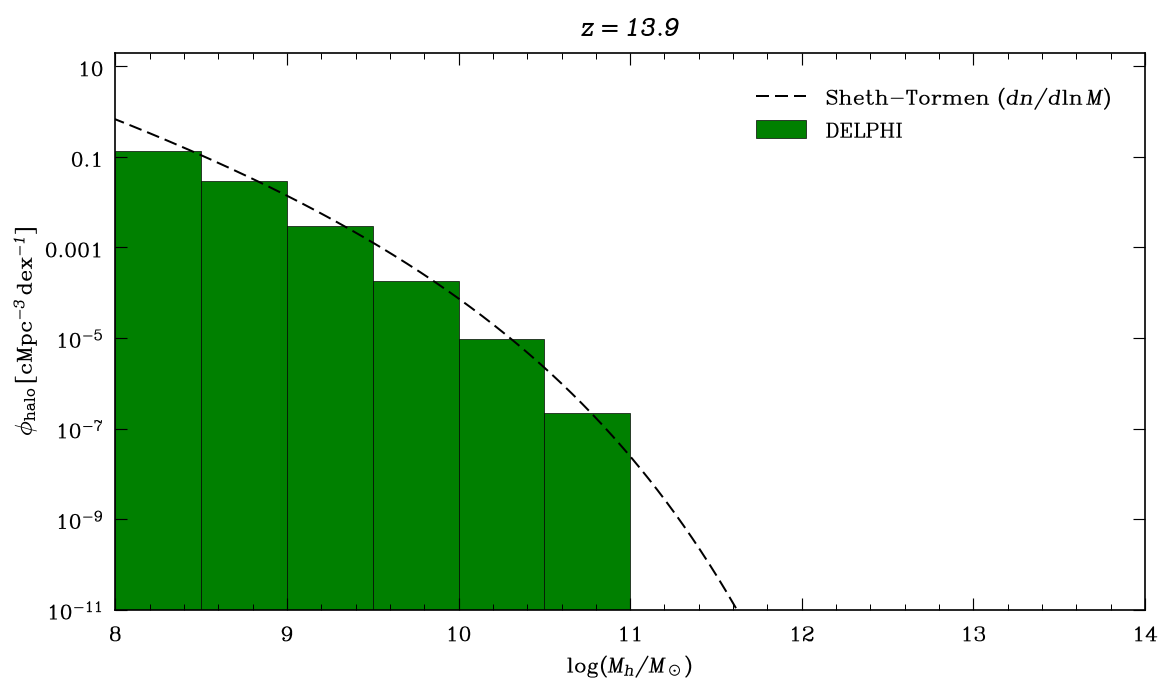

In [12]:
bins = np.arange(8.0, 14.25, 0.5)
for z_i in z_use:
    z = redshifts[z_i - 1]
    hist, edges = np.histogram(logM[z_i], bins=bins, weights=weight[z_i])
    delta_log_Mbin = edges
    #Divide by edges to turn it into units of dex^-1. Per bin to per dex important!!

    phi = hist / np.diff(edges)
    mass_function.update(z=z)
    logM_z = np.log10(mass_function.m / h)        # same units and normalisation as the tree weights (cell 6)
    phi_z = mass_function.dndlnm * h**3
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(edges[:-1], phi, width=np.diff(edges), align="edge", linewidth=0.4, edgecolor="k", facecolor="green", label="DELPHI")

    ax.plot(logM_z, phi_z, "k--", lw=1.2, label=r"Sheth-Tormen ($dn/d\ln M$)")
    ax.set_yscale("log")
    ax.set_xlim(8, 14)
    ax.set_ylim(1e-11, 2e1)
    ax.set_xlabel(r"$\log(M_h/M_\odot)$")
    ax.set_ylabel(r"$\phi_{\mathrm{halo}}\,[\mathrm{cMpc}^{-3}\,\mathrm{dex}^{-1}]$")
    ax.set_title(rf"$z = {z:.1f}$")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()